# Лабораторная работа № 3. Вариант 9
## Трёхмерное моделирование сверхзвукового обтекания сферы

Жуховицкий Александр Дмитриевич, М8О-403Б-23.

Геометрия построена в Autodesk Inventor, сетка — в STAR-CCM+.
Численное решение получено решателем ГАЛА в КПВМ «Egorych».
Ноутбук содержит расчёт нормировочных величин и обработку выгрузок решателя.
Численные поля и история сходимости не заменяются аналитическими оценками.


In [1]:
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
from pathlib import Path
import json

try:
    from IPython.display import display, Math
except ImportError:
    def display(value):
        print(value)

    def Math(value):
        return value

sig = lambda value: np.format_float_positional(
    value, precision=max(0, 2 - math.floor(math.log10(abs(value)))),
    unique=False, fractional=True, trim='k'
)

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif'],
    'font.size': 12,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'figure.dpi': 120,
})

root = Path.cwd()
if not (root / '01_Исходные_материалы').exists():
    root = root.parent
results_dir = root / '05_Результаты'
figures_dir = root / '06_Материалы_отчёта'

## 1. Исходные данные

**Исходные данные:** $M_1=10$, $p_1=1000$ Па, $T_1=250$ К,
$\kappa=1{,}4$, $R=0{,}005$ м, $l_1=20$ мм, $l_2=30$ мм, $l_3=25$ мм.

Расчётная область — сектор с углом $\varphi=5^\circ$.
Центр сферы расположен в точке $x_c=l_1+R$, передняя точка сферы — $x=l_1$.
Полная длина области $L=l_1+2R+l_2$.


In [2]:
mach_1 = 10
p_1 = 1000
t_1 = 250
gamma = 1.4
radius = 0.005
l_1 = 0.020
l_2 = 0.030
l_3 = 0.025
sector_angle = 5

diameter = 2 * radius
center_x = l_1 + radius
domain_length = l_1 + diameter + l_2
sector_fraction = sector_angle / 360

initial_data = pd.DataFrame({
    'Параметр': ['Число Маха', 'Давление, Па', 'Температура, К',
                 'Радиус, мм', 'l1, мм', 'l2, мм', 'l3, мм',
                 'Длина области, мм', 'Координата центра, мм', 'Угол сектора, град'],
    'Значение': [mach_1, p_1, t_1, radius * 1000, l_1 * 1000,
                 l_2 * 1000, l_3 * 1000, domain_length * 1000,
                 center_x * 1000, sector_angle]
})
display(initial_data)

                Параметр  Значение
0             Число Маха      10.0
1           Давление, Па    1000.0
2         Температура, К     250.0
3             Радиус, мм       5.0
4                 l1, мм      20.0
5                 l2, мм      30.0
6                 l3, мм      25.0
7      Длина области, мм      60.0
8  Координата центра, мм      25.0
9     Угол сектора, град       5.0


## 2. Нормировка коэффициента сопротивления

**Исходные данные:** значения раздела 1; сектор $5^\circ$.

Скоростной напор определяется через $a^2=\kappa p/\rho$ и $V=Ma$:

$$
q_1=\frac{\rho_1 V_1^2}{2}=\frac{\kappa p_1 M_1^2}{2}.
$$

Площадь миделя полной идеальной сферы $S_{\mathrm{mid,full}}=\pi R^2$.
Для идеального сектора опорная площадь равна
$S_{\mathrm{ref}}=S_{\mathrm{mid,full}}\varphi/(360^\circ)$:

$$
\begin{aligned}
C_x &= \frac{F_{x,\mathrm{sector}}}{q_1 S_{\mathrm{ref}}}
     = \frac{F_{x,\mathrm{full}}}{q_1 S_{\mathrm{mid,full}}},\\
F_{x,\mathrm{full}} &= \frac{360^\circ}{\varphi}F_{x,\mathrm{sector}}.
\end{aligned}
$$

В выгрузке ГАЛА обозначение $S_{\mathrm{mid}}$ относится к площади проекции
**сеточного сектора**, а не полной сферы. Из-за плоских граней она немного
отличается от идеальной площади $S_{\mathrm{ref}}$.
Дополнительное различие коэффициентов в ветке $S_{\mathrm{ref}}$
количественно объясняется округлением площади до $0{,}011\ \text{см}^2$
при пересчёте или выводе результатов. Проверка по сетке и всем 12 парам
коэффициентов приведена в разделе 11.
В сравнении с экспериментом сохраняется требуемое заданием
$C_x(S_{\mathrm{mid}})=0{,}9284$.


In [3]:
q_1 = gamma * p_1 * mach_1**2 / 2
area_full = math.pi * radius**2
area_sector = area_full * sector_fraction

normalization = pd.DataFrame({
    'Величина': ['Скоростной напор, Па', 'Площадь миделя, м²',
                 'Площадь сектора, м²', 'qS полной сферы, Н', 'qS сектора, Н'],
    'Значение': [q_1, area_full, area_sector, q_1 * area_full, q_1 * area_sector]
})
display(normalization)
display(Math(r'S_{ref} = ' + sig(area_sector) + r'\;\mathrm{m^2}'))

               Величина      Значение
0  Скоростной напор, Па  70000.000000
1    Площадь миделя, м²      0.000079
2   Площадь сектора, м²      0.000001
3    qS полной сферы, Н      5.497787
4         qS сектора, Н      0.076358
S_{ref} = 0.00000109\;\mathrm{m^2}


## 3. Экспериментальные данные

В таблице 2 методички при $M_1=10$ указано $C_{x,\mathrm{exp}}=0{,}86$.
По рисунку 2 в окрестности $M_1=10$ имеем приблизительно
$\delta/d\simeq0{,}06$, с разбросом около $0{,}01$.
Это графическая оценка, а не точное табличное значение:

$$
\delta_{\mathrm{exp}}\simeq 0{,}06\cdot d=0{,}6\ \text{мм}.
$$

Для оценки чувствительности сравнения используется диапазон $0{,}5$–$0{,}7$ мм.

Относительная погрешность из методички:

$$
\varepsilon=\frac{|a-b|}{|a|}\cdot100\%,
$$

где $a$ — экспериментальное значение, $b$ — численное.


In [4]:
cx_exp = 0.86
delta_ratio_exp = 0.06
delta_ratio_spread = 0.01
delta_exp = delta_ratio_exp * diameter
delta_exp_low = (delta_ratio_exp - delta_ratio_spread) * diameter
delta_exp_high = (delta_ratio_exp + delta_ratio_spread) * diameter

def relative_error(reference, numerical):
    return abs(reference - numerical) / abs(reference) * 100

experimental_data = pd.DataFrame({
    'Величина': ['Cx', 'δ/d (приблизительно)', 'δ, мм (приблизительно)',
                 'Нижняя оценка δ, мм', 'Верхняя оценка δ, мм'],
    'Значение': [cx_exp, delta_ratio_exp, delta_exp * 1000,
                 delta_exp_low * 1000, delta_exp_high * 1000]
})
display(experimental_data)

                 Величина  Значение
0                      Cx      0.86
1    δ/d (приблизительно)      0.06
2  δ, мм (приблизительно)      0.60
3     Нижняя оценка δ, мм      0.50
4    Верхняя оценка δ, мм      0.70


## 4. Настройки численного расчёта

Сетка содержит 43 590 ячеек. По углу сектора имеется одна ячейка.
Базовый размер — 0,2 мм, целевой размер на сфере — 0,05 мм.
У стенки построены 20 слоёв общей толщиной 0,3 мм с коэффициентом роста 1,2.

Параметры выполненного расчёта: CFL = 0,4, максимум 20 000 итераций,
локальный шаг по времени, ламинарный совершенный газ.
Температура стенки 300 К принята из шаблона Sphere;
в задании температура стенки отдельно не оговорена.
История невязок записывается каждые 50 итераций.

Расчёт завершён на 20 000-й итерации. Ниже выполнены обработка полей,
измерение отхода ударной волны, построение EPT и Cx и сравнение с экспериментом.


In [5]:
settings = {
    'cells': 43590,
    'base_size_m': 0.0002,
    'wall_size_m': 0.00005,
    'prism_layers': 20,
    'prism_thickness_m': 0.0003,
    'prism_stretching': 1.2,
    'angular_layers': 1,
    'cfl': 0.4,
    'max_iterations': 20000,
    'residual_interval': 50,
    'surface_temperature_K': 300,
    'reference_length_m': diameter,
    'reference_area_m2': area_sector,
    'scenario_id': 'abec156a-bcb0-4b02-b590-877b73cebf48',
    'first_job_id': '3e5c0c36-a36a-4f01-85b4-e245cb1dec1b',
}

reference = {
    'M1': mach_1, 'p1_Pa': p_1, 'T1_K': t_1, 'gamma': gamma,
    'radius_m': radius, 'diameter_m': diameter,
    'l1_m': l_1, 'l2_m': l_2, 'l3_m': l_3,
    'center_x_m': center_x, 'domain_length_m': domain_length,
    'sector_angle_deg': sector_angle, 'q1_Pa': q_1,
    'area_full_m2': area_full, 'area_sector_m2': area_sector,
    'cx_exp': cx_exp, 'delta_exp_m': delta_exp,
    'delta_exp_low_m': delta_exp_low, 'delta_exp_high_m': delta_exp_high,
    'delta_exp_source': 'Приблизительное считывание графика методички',
}

for filename, values in [('reference.json', reference), ('settings.json', settings)]:
    (results_dir / filename).write_text(
        json.dumps(values, ensure_ascii=False, indent=2), encoding='utf-8'
    )
display(pd.DataFrame(settings.items(), columns=['Параметр', 'Значение']))

                 Параметр                              Значение
0                   cells                                 43590
1             base_size_m                                0.0002
2             wall_size_m                               0.00005
3            prism_layers                                    20
4       prism_thickness_m                                0.0003
5        prism_stretching                                   1.2
6          angular_layers                                     1
7                     cfl                                   0.4
8          max_iterations                                 20000
9       residual_interval                                    50
10  surface_temperature_K                                   300
11     reference_length_m                                  0.01
12      reference_area_m2                              0.000001
13            scenario_id  abec156a-bcb0-4b02-b590-877b73cebf48
14           first_job_id  3e5c0c36-a36a

## 5. Схема геометрии

**Исходные данные:** размеры варианта 9 из раздела 1.

На схеме показано меридиональное сечение. В Inventor оно повёрнуто
вокруг оси $x$ на $5^\circ$ симметрично относительно плоскости эскиза.
Расчётная область находится снаружи сферы. Обе боковые плоскости сектора
имеют условие симметрии. Верхняя и правая границы образуют EXIT.
Схема служит пояснением размеров; исходные IPT, STEP и снимки Inventor
сохранены отдельно.


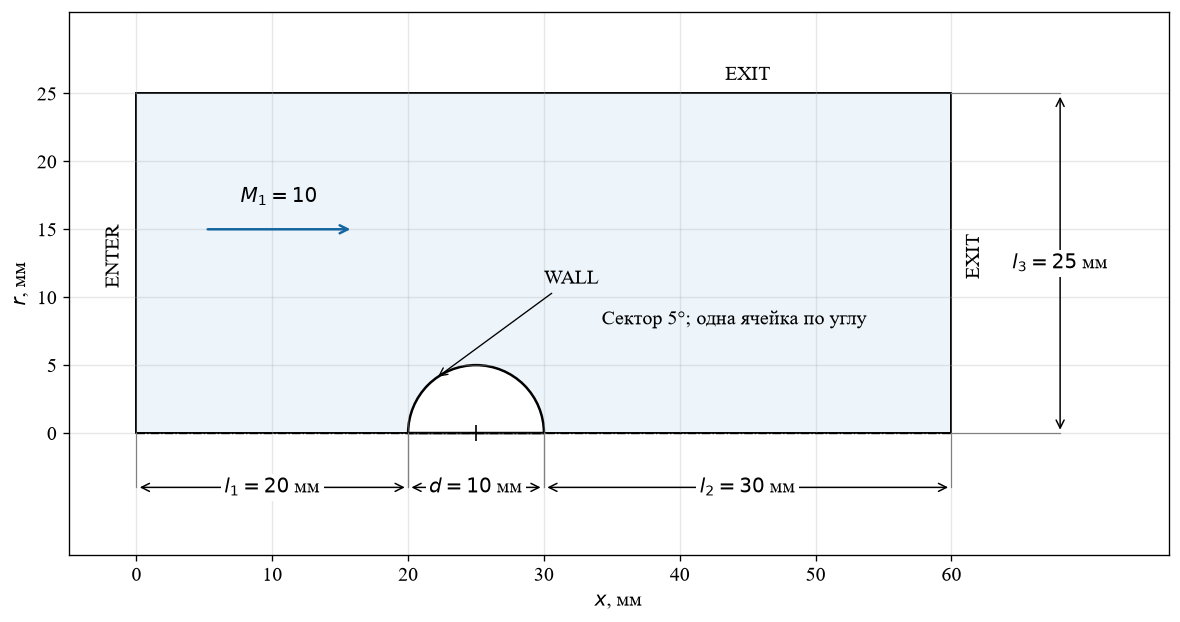

In [6]:
from matplotlib.patches import Wedge, Rectangle
from matplotlib.ticker import FuncFormatter

def comma_tick(value, position):
    return f'{value:g}'.replace('.', ',')

def dimension(ax, start, end, label, offset):
    start = np.array(start, dtype=float)
    end = np.array(end, dtype=float)
    shift = np.array(offset, dtype=float)
    for point in [start, end]:
        ax.plot(*np.array([point, point + shift]).T, color='0.5', lw=0.7)
    ax.annotate('', end + shift, start + shift,
                arrowprops={'arrowstyle': '<->', 'lw': 0.9})
    midpoint = (start + end) / 2 + shift
    ax.text(*midpoint, label, ha='center', va='center',
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 2})

fig, ax = plt.subplots(figsize=(10, 6))
ax.add_patch(Rectangle((0, 0), domain_length * 1000, l_3 * 1000,
                       facecolor='#edf4fa', edgecolor='black', lw=1.2))
ax.add_patch(Wedge((center_x * 1000, 0), radius * 1000, 0, 180,
                   facecolor='white', edgecolor='black', lw=1.5))
ax.plot([0, domain_length * 1000], [0, 0], 'k-.', lw=0.8)
ax.plot(center_x * 1000, 0, '+', color='black', ms=10)
ax.annotate('', (16, 15), (5, 15),
            arrowprops={'arrowstyle': '->', 'lw': 1.5, 'color': '#1565a0'})
ax.text(10.5, 17, '$M_1=10$', ha='center')
ax.text(-1, 13, 'ENTER', rotation=90, ha='right', va='center')
ax.text(45, 26, 'EXIT', ha='center')
ax.text(61, 13, 'EXIT', rotation=90, ha='left', va='center')
ax.annotate('WALL', (22, 4), (30, 11),
            arrowprops={'arrowstyle': '->', 'lw': 0.8})
dimension(ax, [0, 0], [l_1 * 1000, 0], '$l_1=20$ мм', [0, -4])
dimension(ax, [20, 0], [30, 0], '$d=10$ мм', [0, -4])
dimension(ax, [30, 0], [60, 0], '$l_2=30$ мм', [0, -4])
dimension(ax, [60, 0], [60, 25], '$l_3=25$ мм', [8, 0])
ax.text(44, 8, 'Сектор 5°; одна ячейка по углу', ha='center')
ax.set(xlim=(-5, 76), ylim=(-9, 31), aspect='equal',
       xlabel='$x$, мм', ylabel='$r$, мм')
ax.set_xticks(np.arange(0, 61, 10))
ax.set_yticks(np.arange(0, 26, 5))
ax.xaxis.set_major_formatter(FuncFormatter(comma_tick))
ax.yaxis.set_major_formatter(FuncFormatter(comma_tick))
fig.tight_layout()
fig.savefig(figures_dir / 'geometry_scheme.png', dpi=240, bbox_inches='tight')
plt.show()

## 6. Чтение полей и построение сечения

Для обработки используются значения в центрах исходных ячеек ГАЛА.
Координаты узлов читаются из DAT, размерности полей сохраняются в СИ.
Сечение строится в координатах $(x,r)$, где $r=\sqrt{y^2+z^2}$.
Каждому многоугольнику соответствует одна исходная объёмная ячейка.
Цветовые поля выводятся без сглаживания между ячейками.


In [7]:
import re
from matplotlib.collections import PolyCollection

def read_volume(path):
    text = path.read_text(encoding='utf-8')
    header, values = text.split('VARLOCATION=', 1)
    values = values.split('\n', 1)[1]
    names = re.findall(r'"([^"]+)"', header.split('VARIABLES')[1].split('ZONE')[0])
    node_count = int(re.search(r'NODES\s*=\s*(\d+)', header).group(1))
    cell_count = int(re.search(r'ELEMENTS\s*=\s*(\d+)', header).group(1))
    if 'FEBRICK' not in header or 'BLOCK' not in header:
        raise ValueError('Ожидалась блочная запись FEBRICK')
    raw = np.fromstring(values.replace('D+', 'E+').replace('D-', 'E-'), sep=' ')
    field_count = len(names) - 3
    assert raw.size == 3 * node_count + (field_count + 8) * cell_count
    assert np.isfinite(raw).all()
    xyz = raw[:3 * node_count].reshape(3, node_count).T
    boundary = 3 * node_count + field_count * cell_count
    field_values = raw[3 * node_count:boundary].reshape(field_count, cell_count)
    fields = dict(zip(names[3:], field_values))
    connections = raw[boundary:].astype(int).reshape(cell_count, 8) - 1
    assert connections.min() == 0 and connections.max() < node_count
    assert (fields['P'] > 0).all() and (fields['RO'] > 0).all()
    return xyz, fields, connections

def meridian_cells(xyz, connections):
    projected = np.column_stack([xyz[:, 0], np.hypot(xyz[:, 1], xyz[:, 2])])
    polygons = []
    for indices in connections:
        points = np.unique(np.round(projected[indices], 11), axis=0)
        center = points.mean(axis=0)
        angles = np.arctan2(points[:, 1] - center[1], points[:, 0] - center[0])
        polygons.append(points[np.argsort(angles)])
    centers = np.array([polygon.mean(axis=0) for polygon in polygons])
    return polygons, centers

In [8]:
def field_picture(polygons, values, label, filename, limits=None, bounds=None, norm=None):
    fig, ax = plt.subplots(figsize=(10, 4.8))
    collection = PolyCollection([polygon * 1000 for polygon in polygons],
                                array=values, cmap='turbo', norm=norm, edgecolors='none',
                                rasterized=True, antialiaseds=False)
    if limits is not None:
        collection.set_clim(*limits)
    ax.add_collection(collection)
    ax.add_patch(Wedge((center_x * 1000, 0), radius * 1000, 0, 180,
                       facecolor='white', edgecolor='black', lw=1.1))
    if bounds is None:
        bounds = (0, domain_length * 1000, 0, l_3 * 1000)
    ax.set(xlim=bounds[:2], ylim=bounds[2:], aspect='equal',
           xlabel='$x$, мм', ylabel='$r$, мм')
    ax.xaxis.set_major_formatter(FuncFormatter(comma_tick))
    ax.yaxis.set_major_formatter(FuncFormatter(comma_tick))
    ax.grid(False)
    colorbar = fig.colorbar(collection, ax=ax, pad=0.025, fraction=0.035)
    colorbar.set_label(label)
    colorbar.ax.yaxis.set_major_formatter(FuncFormatter(comma_tick))
    fig.tight_layout()
    fig.savefig(figures_dir / filename, dpi=240, bbox_inches='tight')
    plt.show()

## 7. Измерение отхода ударной волны

**Исходные данные:** поле давления и координаты исходных ячеек;
передняя точка сферы $x_n=l_1$.

Выбираются ячейки перед сферой, имеющие ребро на оси $r=0$.
Их значения относятся к ближайшему к оси ряду центров ячеек.
Положение волны оценивается серединой пары соседних центров,
между которыми величина $\Delta p/\Delta x$ максимальна:

$$
x_s=\frac{x_i+x_{i+1}}{2},\qquad \delta=x_n-x_s.
$$

Половина расстояния между этими центрами характеризует разрешение
измерения по данной сетке. Это не статистический доверительный интервал.
В качестве дополнительной проверки определяется максимум
$\Delta\rho/\Delta x$ вне пристеночного слоя толщиной 0,3 мм.
Около холодной стенки плотность также резко растёт, поэтому глобальный
максимум её градиента нельзя автоматически считать ударной волной.
Экспериментальное значение не используется
при поиске численного положения волны.


In [9]:
def measure_shock(polygons, centers, fields):
    on_axis = np.array([np.count_nonzero(abs(polygon[:, 1]) < 1e-9) >= 2
                        for polygon in polygons])
    indices = np.flatnonzero(on_axis & (centers[:, 0] < l_1))
    indices = indices[np.argsort(centers[indices, 0])]
    x = centers[indices, 0]
    pressure = fields['P'][indices]
    density = fields['RO'][indices]
    dx = np.diff(x)
    assert len(indices) > 10 and (dx > 0).all()
    pressure_gradient = np.diff(pressure) / dx
    density_gradient = np.diff(density) / dx
    i = int(np.argmax(pressure_gradient))
    j_global = int(np.argmax(density_gradient))
    midpoints = (x[:-1] + x[1:]) / 2
    outside_wall_layers = midpoints < l_1 - settings['prism_thickness_m']
    j = int(np.argmax(np.where(outside_wall_layers, density_gradient, -np.inf)))
    shock_x = (x[i] + x[i + 1]) / 2
    shock_density_x = (x[j] + x[j + 1]) / 2
    profile = pd.DataFrame({
        'cell_1based': indices + 1,
        'x_m': x, 'r_m': centers[indices, 1],
        'p_Pa': pressure, 'rho_kg_m3': density,
        'T_K': fields['T'][indices], 'M': fields['M'][indices],
    })
    measurement = {
        'nose_x_m': l_1,
        'shock_x_m': float(shock_x),
        'delta_m': float(l_1 - shock_x),
        'half_interval_m': float(dx[i] / 2),
        'left_cell_1based': int(indices[i] + 1),
        'right_cell_1based': int(indices[i + 1] + 1),
        'left_x_m': float(x[i]), 'right_x_m': float(x[i + 1]),
        'left_r_m': float(centers[indices[i], 1]),
        'right_r_m': float(centers[indices[i + 1], 1]),
        'density_global_gradient_x_m': float(midpoints[j_global]),
        'density_shock_x_m': float(shock_density_x),
        'density_delta_m': float(l_1 - shock_density_x),
    }
    return profile, measurement

## 8. Линии тока

Линии тока строятся по численно рассчитанным компонентам скорости.
В меридиональном сечении используются продольная скорость $V_x$ и радиальная
составляющая $V_r=(yV_y+zV_z)/r$, где $r=\sqrt{y^2+z^2}$.
Проекция вычисляется в центрах ячеек, для которых $r>0$.

Для интегрирования скорость линейно интерполируется между центрами
ячеек на регулярную сетку. Треугольники интерполяции, пересекающие
тело, исключаются. Цветовые поля в разделе 6 при этом остаются
непосредственными значениями исходных ячеек.

Показываются общий вид, область передней точки сферы и донная область.


In [10]:
import matplotlib.tri as mtri

def velocity_interpolators(centers, fields, radial_velocity):
    triangulation = mtri.Triangulation(centers[:, 0], centers[:, 1])
    points = centers[triangulation.triangles]
    sphere_center = np.array([center_x, 0])
    mask = np.zeros(len(points), dtype=bool)
    for edge in [(0, 1), (1, 2), (2, 0)]:
        start = points[:, edge[0]]
        step = points[:, edge[1]] - start
        t = np.sum((sphere_center - start) * step, axis=1)
        t = np.clip(t / np.sum(step**2, axis=1), 0, 1)
        closest = start + t[:, None] * step
        mask |= np.sum((closest - sphere_center)**2, axis=1) < radius**2
    triangulation.set_mask(mask)
    u = mtri.LinearTriInterpolator(triangulation, fields['VX'])
    v = mtri.LinearTriInterpolator(triangulation, radial_velocity)
    return u, v

def streamline_picture(u, v, bounds, filename, density=1.8):
    x = np.linspace(bounds[0], bounds[1], 650)
    r = np.linspace(bounds[2], bounds[3], 350)
    xx, rr = np.meshgrid(x, r)
    vx = u(xx / 1000, rr / 1000)
    vr = v(xx / 1000, rr / 1000)
    fig, ax = plt.subplots(figsize=(10, 5.2))
    ax.streamplot(x, r, vx, vr, density=density, linewidth=0.7,
                  color='#185b89', arrowsize=1, minlength=0.05)
    ax.add_patch(Wedge((center_x * 1000, 0), radius * 1000, 0, 180,
                       facecolor='0.92', edgecolor='black', lw=1.2))
    ax.set(xlim=bounds[:2], ylim=bounds[2:], aspect='equal',
           xlabel='$x$, мм', ylabel='$r$, мм')
    ax.xaxis.set_major_formatter(FuncFormatter(comma_tick))
    ax.yaxis.set_major_formatter(FuncFormatter(comma_tick))
    fig.tight_layout()
    fig.savefig(figures_dir / filename, dpi=240, bbox_inches='tight')
    plt.show()

## 9. Обработка выгрузки решателя

Ниже читаются сохранённые поля, проверяются размеры области, число
ячеек и значения набегающего потока. Таблицы и изображения получаются
непосредственным выполнением ячеек, а не ручным вводом результатов.


In [11]:
volume_path = results_dir / 'volume[0020000].dat'
xyz, fields, connections = read_volume(volume_path)
polygons, centers = meridian_cells(xyz, connections)
assert len(connections) == settings['cells']
assert np.isclose(xyz[:, 0].min(), 0, atol=1e-7)
assert np.isclose(xyz[:, 0].max(), domain_length, atol=1e-7)
assert np.isclose(np.hypot(xyz[:, 1], xyz[:, 2]).max(), l_3, atol=1e-7)

upstream = centers[:, 0] < l_1 / 10
upstream_values = {key: float(np.median(values[upstream]))
                   for key, values in fields.items()}
field_statistics = {
    key: {'min': float(values.min()), 'max': float(values.max())}
    for key, values in fields.items()
}
assert abs(upstream_values['P'] / p_1 - 1) < 1e-4
assert abs(upstream_values['T'] / t_1 - 1) < 1e-4
assert abs(upstream_values['M'] / mach_1 - 1) < 1e-4
display(pd.DataFrame(field_statistics).T)
display(pd.DataFrame(upstream_values.items(), columns=['Поле', 'Набегающий поток']))
print('Узлов:', len(xyz), 'Ячеек:', len(connections))
gas_R = float(np.median(fields['P'] / (fields['RO'] * fields['T'])))
eos_error = float(np.max(abs(fields['P'] / (fields['RO'] * gas_R * fields['T']) - 1)))
speed = np.sqrt(fields['VX']**2 + fields['VY']**2 + fields['VZ']**2)
mach_from_fields = speed / np.sqrt(gamma * fields['P'] / fields['RO'])
mach_error = float(np.max(abs(mach_from_fields - fields['M'])))
assert (fields['T'] > 0).all() and (fields['M'] >= 0).all()
assert eos_error < 1e-10
# Сверка отдельно выгруженного M с компонентами скорости: абсолютный допуск 0,001.
assert mach_error < 1e-3, mach_error
gamma_error = float(np.max(abs(1 + fields['P'] / (fields['RO'] * fields['EI']) - gamma)))
assert gamma_error < 1e-10
print('R газа, Дж/(кг·К):', sig(gas_R))
print('Погрешность уравнения состояния:', eos_error)
print('Максимальная разность чисел Маха:', mach_error)


              min           max
VX    -787.456251  3.167766e+03
VY   -1075.927143  1.367006e+03
VZ      -0.000003  2.285495e-06
P       93.143105  1.481087e+05
RO       0.000806  5.235077e-01
M        0.000505  1.000000e+01
T      250.000000  5.498729e+03
MT       0.000000  0.000000e+00
EI  179191.810345  3.941309e+06
TU       0.000000  0.000000e+00
Q        0.000000  0.000000e+00
   Поле  Набегающий поток
0    VX      3.167766e+03
1    VY     -8.304907e-15
2    VZ     -1.368786e-13
3     P      1.000000e+03
4    RO      1.395153e-02
5     M      1.000000e+01
6     T      2.500000e+02
7    MT      0.000000e+00
8    EI      1.791918e+05
9    TU      0.000000e+00
10    Q      0.000000e+00
Узлов: 88044 Ячеек: 43590
R газа, Дж/(кг·К): 287.
Погрешность уравнения состояния: 1.000088900582341e-12
Максимальная разность чисел Маха: 0.0005907949417256475


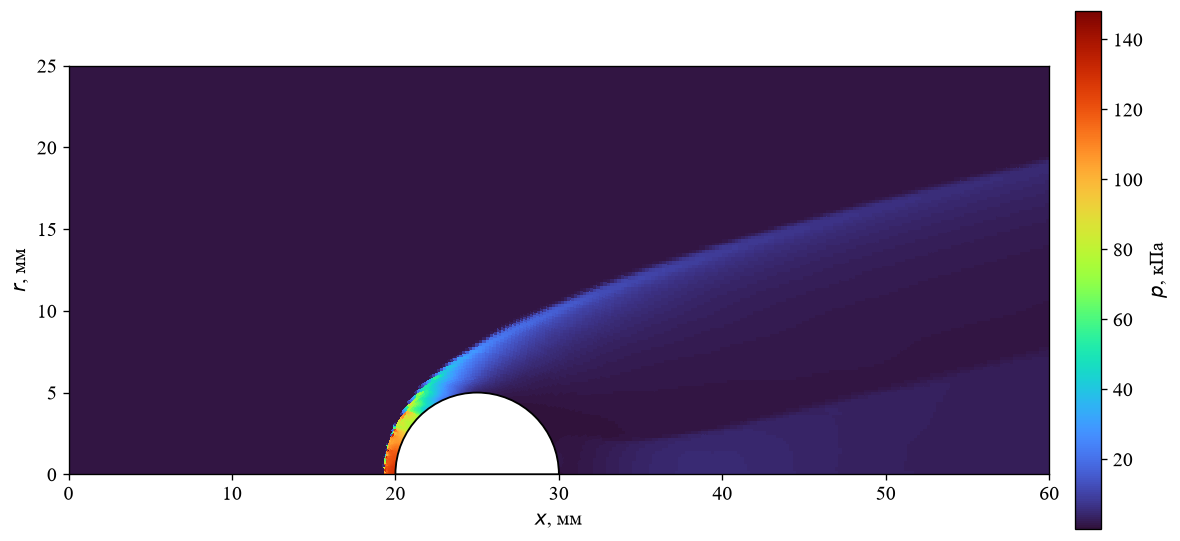

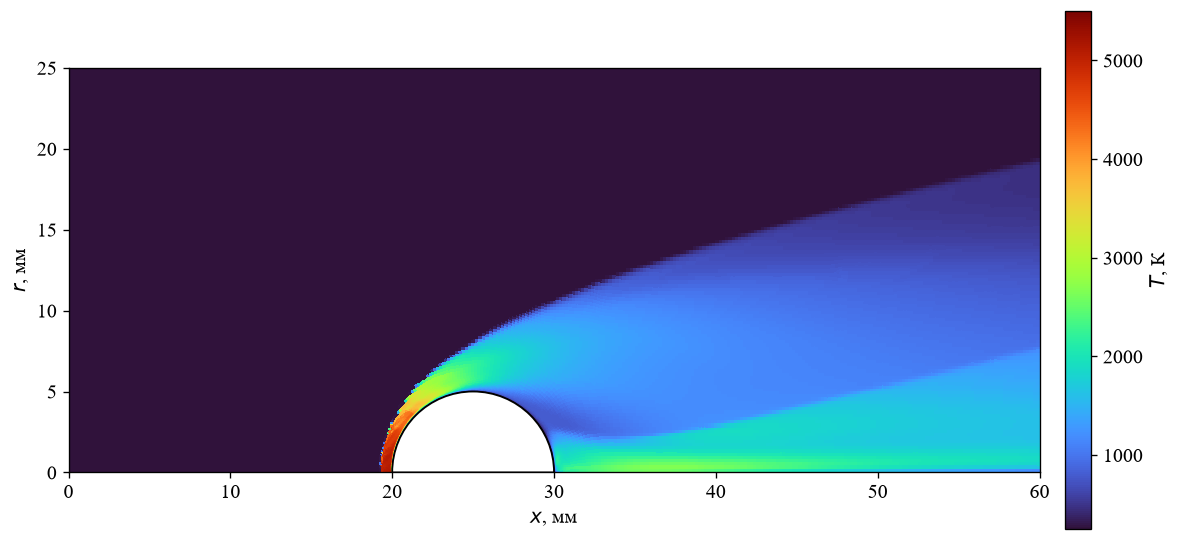

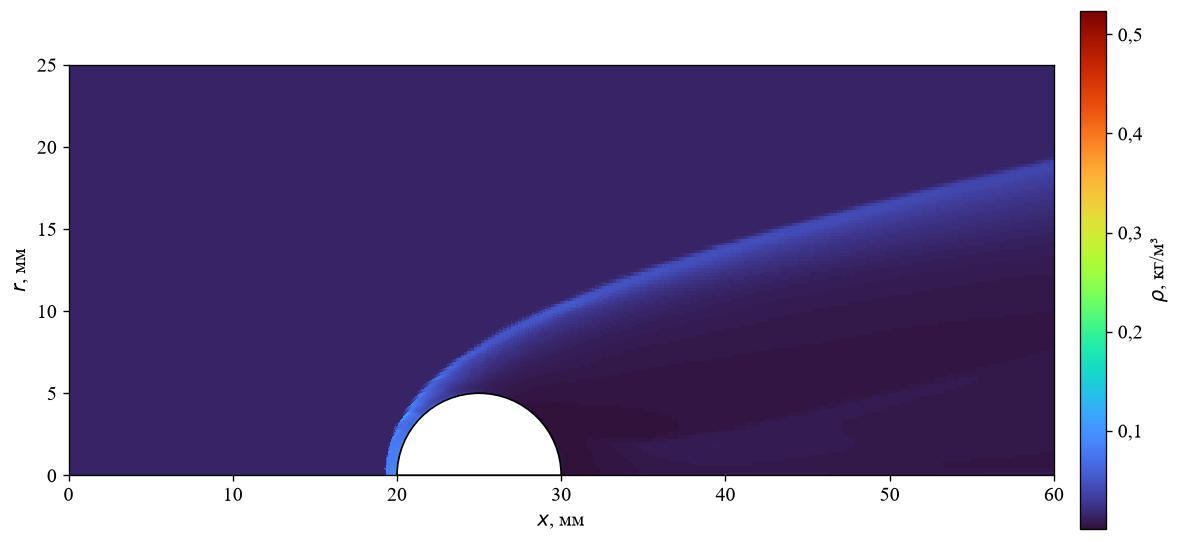

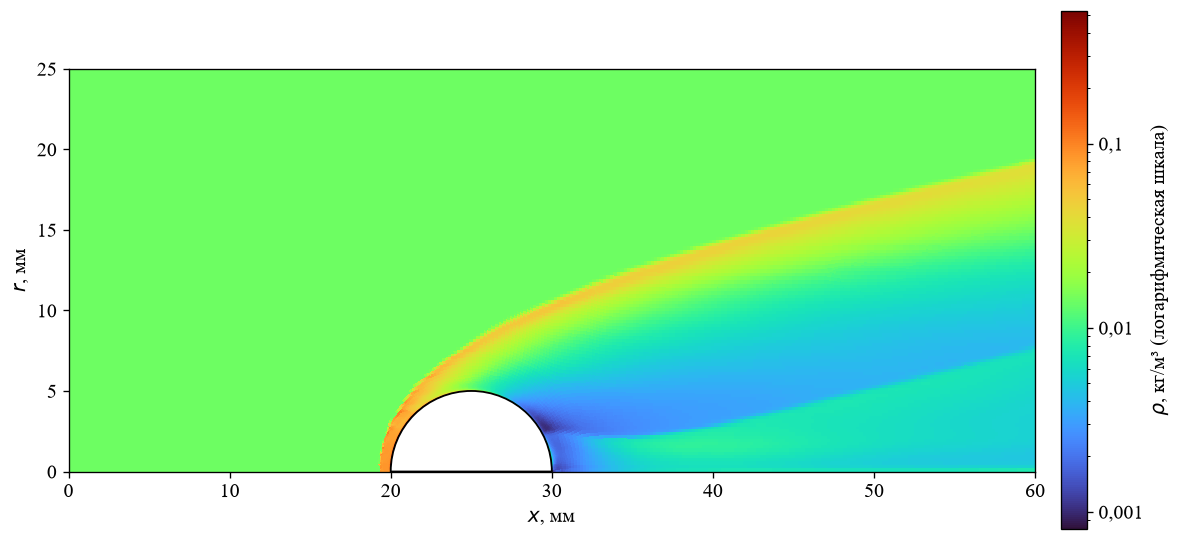

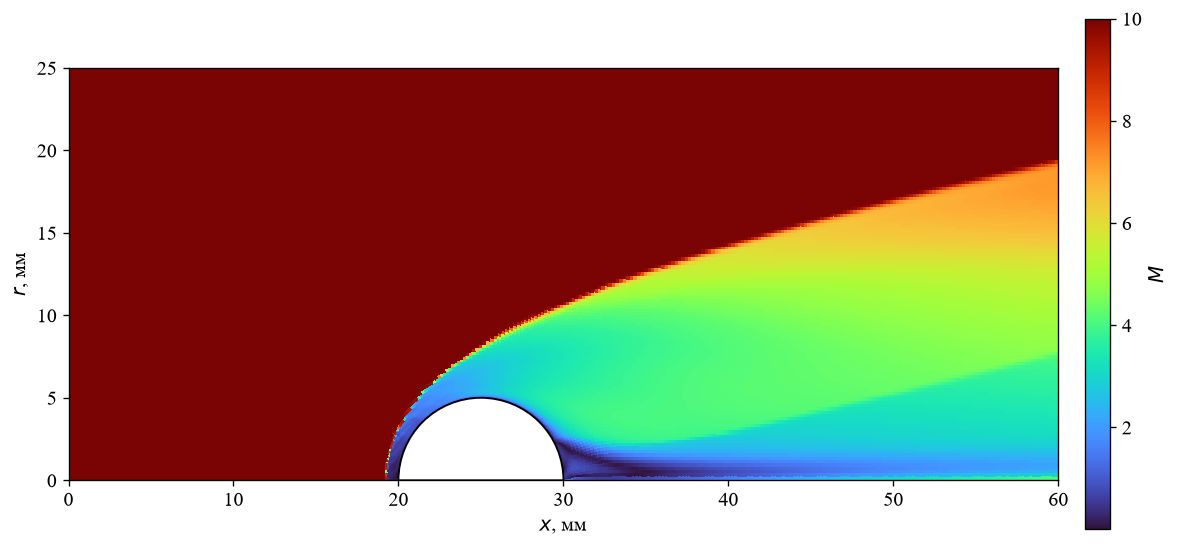

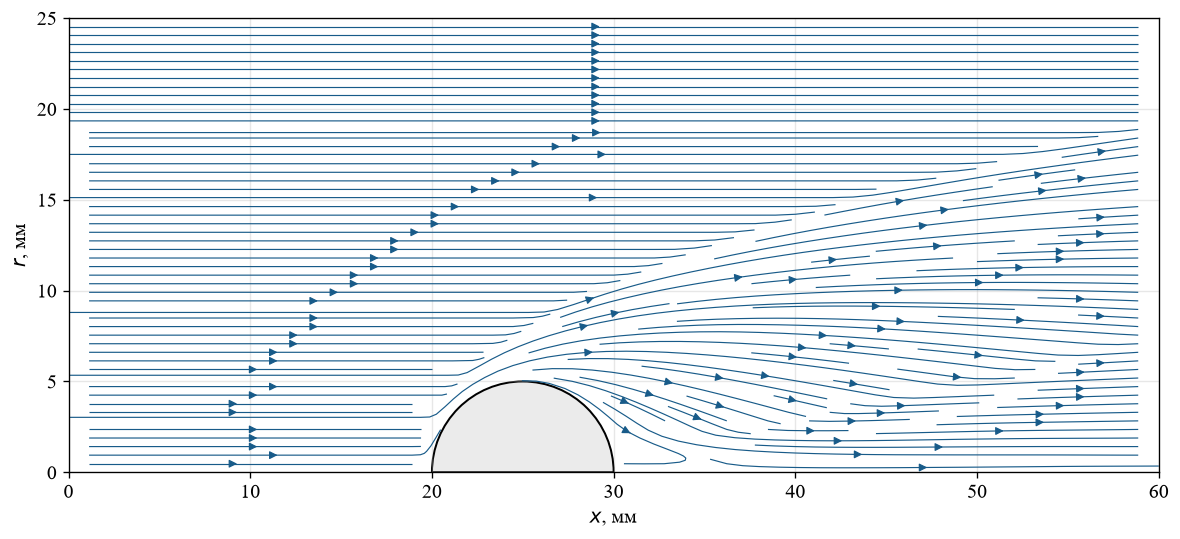

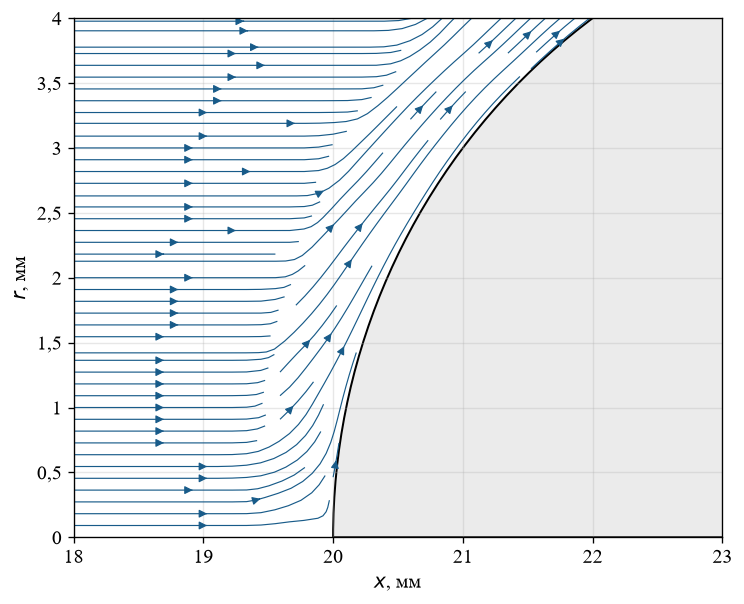

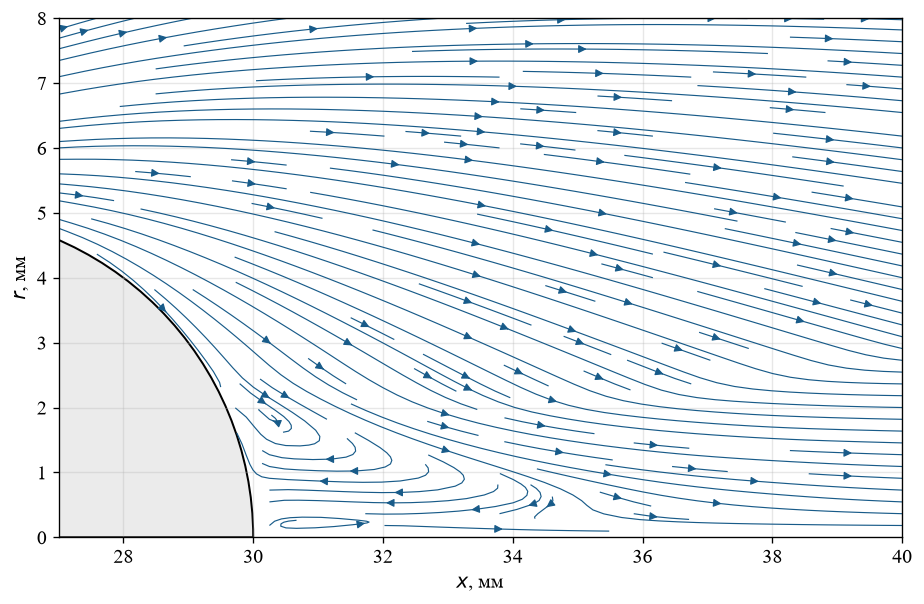

In [12]:
field_picture(polygons, fields['P'] / 1000, '$p$, кПа', 'pressure.png')
field_picture(polygons, fields['T'], '$T$, К', 'temperature.png')
field_picture(polygons, fields['RO'], r'$\rho$, кг/м³', 'density.png')
from matplotlib.colors import LogNorm
field_picture(polygons, fields['RO'], r'$\rho$, кг/м³ (логарифмическая шкала)',
              'density_log.png', norm=LogNorm())
field_picture(polygons, fields['M'], '$M$', 'mach.png')

cell_xyz = xyz[connections].mean(axis=1)
cell_radius = np.hypot(cell_xyz[:, 1], cell_xyz[:, 2])
assert (cell_radius > 0).all()
radial_velocity = (fields['VY'] * cell_xyz[:, 1] + fields['VZ'] * cell_xyz[:, 2]) / cell_radius
u, v = velocity_interpolators(centers, fields, radial_velocity)
streamline_picture(u, v, (0, 60, 0, 25), 'streamlines_full.png')
streamline_picture(u, v, (18, 23, 0, 4), 'streamlines_nose.png', 1.5)
streamline_picture(u, v, (27, 40, 0, 8), 'streamlines_wake.png', 1.5)

                       Величина     Значение
0                      nose_x_m     0.020000
1                     shock_x_m     0.019340
2                       delta_m     0.000660
3               half_interval_m     0.000066
4              left_cell_1based  4657.000000
5             right_cell_1based  4754.000000
6                      left_x_m     0.019274
7                     right_x_m     0.019407
8                      left_r_m     0.000066
9                     right_r_m     0.000053
10  density_global_gradient_x_m     0.019998
11            density_shock_x_m     0.019340
12              density_delta_m     0.000660


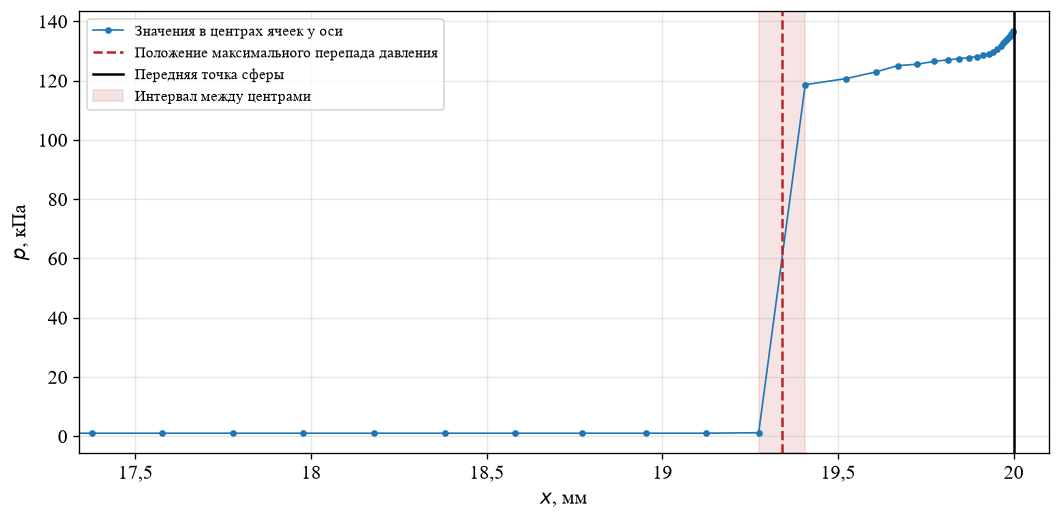

In [13]:
axis_profile, shock = measure_shock(polygons, centers, fields)
axis_profile.to_csv(results_dir / 'axis_profile.csv', index=False)
display(pd.DataFrame(shock.items(), columns=['Величина', 'Значение']))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(axis_profile['x_m'] * 1000, axis_profile['p_Pa'] / 1000,
        'o-', ms=3, lw=1, label='Значения в центрах ячеек у оси')
ax.axvline(shock['shock_x_m'] * 1000, color='#b62727', ls='--',
           label='Положение максимального перепада давления')
ax.axvline(l_1 * 1000, color='black', label='Передняя точка сферы')
ax.axvspan(shock['left_x_m'] * 1000, shock['right_x_m'] * 1000,
           color='#b62727', alpha=0.12, label='Интервал между центрами')
ax.set(xlim=(max(0, shock['shock_x_m'] * 1000 - 2), 20.1),
       xlabel='$x$, мм', ylabel='$p$, кПа')
ax.xaxis.set_major_formatter(FuncFormatter(comma_tick))
ax.yaxis.set_major_formatter(FuncFormatter(comma_tick))
ax.legend(fontsize=9, loc='upper left')
fig.tight_layout()
fig.savefig(figures_dir / 'axis_pressure.png', dpi=240, bbox_inches='tight')
plt.show()

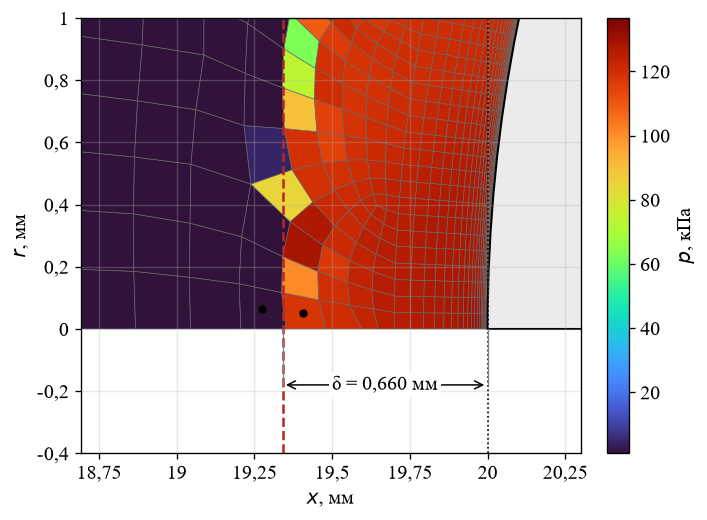

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x_s = shock['shock_x_m'] * 1000
selected = (centers[:, 0] * 1000 > x_s - 0.8) & (centers[:, 0] < l_1 + 0.0002)
selected &= centers[:, 1] < 0.0012
ids = np.flatnonzero(selected)
collection = PolyCollection([polygons[i] * 1000 for i in ids],
                            array=fields['P'][ids] / 1000,
                            cmap='turbo', edgecolors='0.4', linewidths=0.4)
ax.add_collection(collection)
ax.add_patch(Wedge((center_x * 1000, 0), radius * 1000, 0, 180,
                   facecolor='0.92', edgecolor='black', lw=1.2))
ax.axvline(x_s, color='#b62727', ls='--', lw=1.5)
ax.axvline(l_1 * 1000, color='black', ls=':', lw=1)
for key in ['left', 'right']:
    ax.plot(shock[key + '_x_m'] * 1000, shock[key + '_r_m'] * 1000,
            'ko', ms=4)
dimension(ax, [x_s, 0], [l_1 * 1000, 0],
          'δ = ' + sig(shock['delta_m'] * 1000).replace('.', ',') + ' мм',
          [0, -0.18])
ax.set(xlim=(x_s - 0.65, 20.3), ylim=(-0.4, 1.0), aspect='equal',
       xlabel='$x$, мм', ylabel='$r$, мм')
ax.xaxis.set_major_formatter(FuncFormatter(comma_tick))
ax.yaxis.set_major_formatter(FuncFormatter(comma_tick))
fig.colorbar(collection, ax=ax, pad=0.025, label='$p$, кПа')
fig.tight_layout()
fig.savefig(figures_dir / 'shock_measurement.png', dpi=240, bbox_inches='tight')
plt.show()

## 10. История итераций и сравнение с экспериментом

Величина EPT берётся из файла невязок. Коэффициенты давления, трения
и суммарного сопротивления читаются из протокола ГАЛА.
Для оценки установления сопротивления рассматриваются последние
2000 итераций: минимум, максимум, относительный размах и изменение
между началом и концом этого интервала. Это характеристики итерационного
процесса с локальным шагом, а не осреднение нестационарного течения
по физическому времени.


In [15]:
residuals_path = results_dir / 'residuals.csv'
residuals = pd.read_csv(residuals_path)
protocol_residuals = pd.read_csv(results_dir / 'residuals_from_protocol.csv')
assert np.array_equal(residuals['iteration'], protocol_residuals['iteration'])
assert np.allclose(residuals[['EPT', 'EPI']],
                   protocol_residuals[['EPT', 'EPI']], rtol=1e-12, atol=0)
stdout = (root / '04_Расчёт' / 'solver_stdout.txt').read_text(encoding='utf-8')
number = r'([+\-\d.E]+)'
pattern = (r'Iterations\s*=\s*(\d+).*?Cxp\s*=\s*' + number
           + r'.*?Cxf\s*=\s*' + number + r'.*?\bCx\s*=\s*' + number)
rows = re.findall(pattern, stdout, flags=re.S)
assert rows, 'История коэффициента сопротивления не найдена'
coefficients = pd.DataFrame(rows, columns=['iteration', 'Cxp', 'Cxf', 'Cx'])
coefficients = coefficients.astype(float).drop_duplicates('iteration', keep='last')
coefficients['iteration'] = coefficients['iteration'].astype(int)
coefficients = coefficients.sort_values('iteration')
# В протоколе коэффициенты напечатаны с четырьмя значащими цифрами.
printed = coefficients[['Cxp', 'Cxf', 'Cx']].to_numpy()
rounding_bound = (0.5 * 10**(np.floor(np.log10(abs(printed))) - 3)).sum(axis=1)
sum_error = abs(coefficients['Cxp'] + coefficients['Cxf'] - coefficients['Cx'])
assert np.all(sum_error <= rounding_bound + 1e-12)
assert int(residuals['iteration'].iloc[-1]) == int(coefficients['iteration'].iloc[-1])
coefficients.to_csv(results_dir / 'coefficients.csv', index=False)

last_iteration = int(residuals['iteration'].iloc[-1])
tail_r = residuals[residuals['iteration'] >= last_iteration - 2000]
tail_c = coefficients[coefficients['iteration'] >= last_iteration - 2000]
cx = float(coefficients['Cx'].iloc[-1])
convergence = {
    'last_iteration': last_iteration,
    'first_EPT': float(residuals['EPT'].iloc[0]),
    'last_EPT': float(residuals['EPT'].iloc[-1]),
    'tail_EPT_min': float(tail_r['EPT'].min()),
    'tail_EPT_max': float(tail_r['EPT'].max()),
    'tail_Cx_min': float(tail_c['Cx'].min()),
    'tail_Cx_max': float(tail_c['Cx'].max()),
    'tail_Cx_mean': float(tail_c['Cx'].mean()),
    'tail_Cx_range_percent': float(np.ptp(tail_c['Cx']) / tail_c['Cx'].mean() * 100),
    'tail_Cx_drift_percent': float(abs(tail_c['Cx'].iloc[-1] - tail_c['Cx'].iloc[0])
                                  / tail_c['Cx'].mean() * 100),
    'Cx': cx, 'Cxp': float(coefficients['Cxp'].iloc[-1]),
    'Cxf': float(coefficients['Cxf'].iloc[-1]),
}
display(pd.DataFrame(convergence.items(), columns=['Показатель', 'Значение']))

               Показатель      Значение
0          last_iteration  20000.000000
1               first_EPT      0.042840
2                last_EPT      0.000437
3            tail_EPT_min      0.000415
4            tail_EPT_max      0.032170
5             tail_Cx_min      0.926200
6             tail_Cx_max      0.928800
7            tail_Cx_mean      0.927411
8   tail_Cx_range_percent      0.280350
9   tail_Cx_drift_percent      0.237219
10                     Cx      0.928400
11                    Cxp      0.890200
12                    Cxf      0.038190


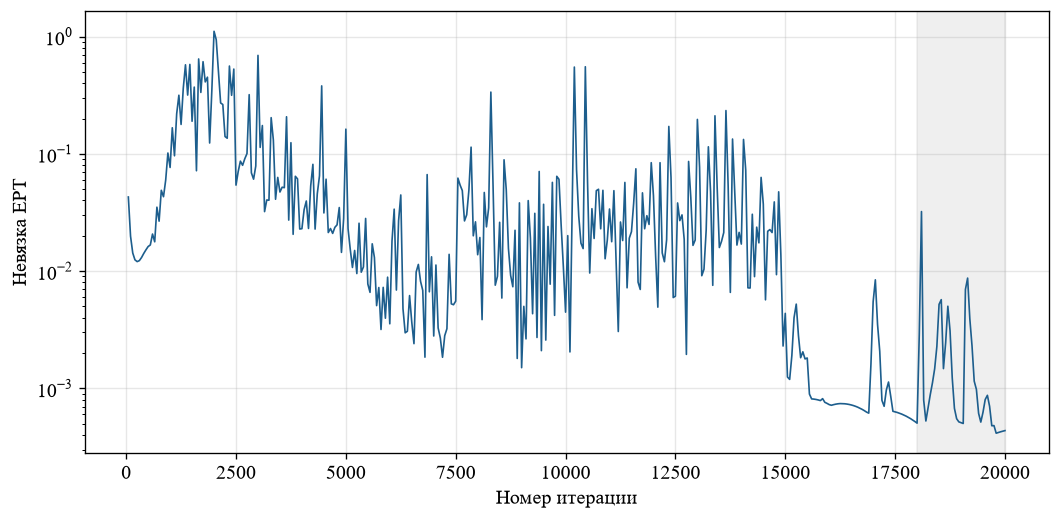

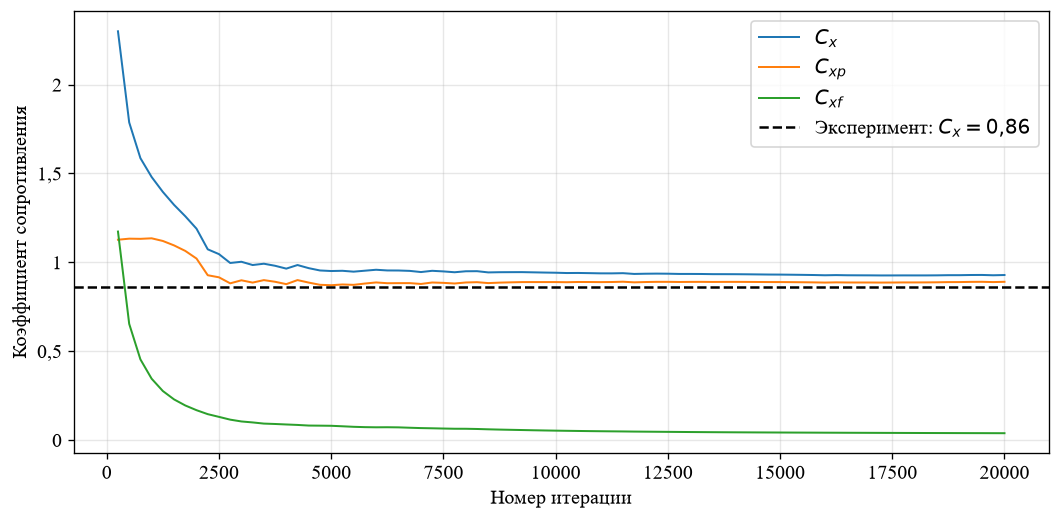

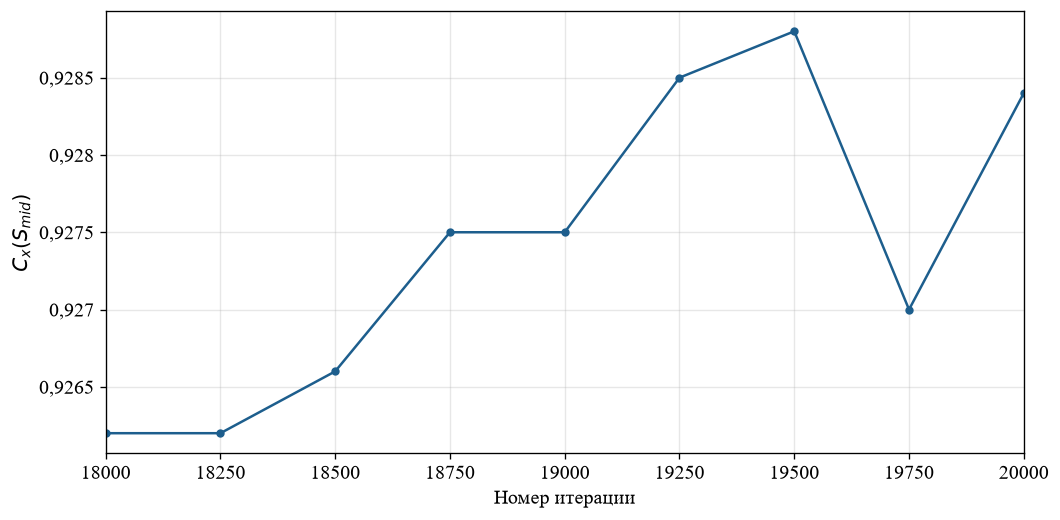

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.semilogy(residuals['iteration'], residuals['EPT'], color='#1d5e8d', lw=1)
ax.set(xlabel='Номер итерации', ylabel='Невязка EPT')
ax.axvspan(last_iteration - 2000, last_iteration, color='0.7', alpha=0.2)
fig.tight_layout()
fig.savefig(figures_dir / 'ept.png', dpi=240, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
for key, label in [('Cx', '$C_x$'), ('Cxp', '$C_{xp}$'), ('Cxf', '$C_{xf}$')]:
    ax.plot(coefficients['iteration'], coefficients[key], lw=1.2, label=label)
ax.axhline(cx_exp, color='black', ls='--', label='Эксперимент: $C_x=0{,}86$')
ax.set(xlabel='Номер итерации', ylabel='Коэффициент сопротивления')
ax.yaxis.set_major_formatter(FuncFormatter(comma_tick))
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / 'cx_history.png', dpi=240, bbox_inches='tight')
plt.show()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(tail_c['iteration'], tail_c['Cx'], 'o-', color='#1d5e8d', ms=4)
ax.set(xlabel='Номер итерации', ylabel='$C_x(S_{mid})$',
       xlim=(last_iteration - 2000, last_iteration))
ax.yaxis.set_major_formatter(FuncFormatter(comma_tick))
fig.tight_layout()
fig.savefig(figures_dir / 'cx_tail.png', dpi=240, bbox_inches='tight')
plt.show()


In [17]:
delta = shock['delta_m']
comparison = pd.DataFrame({
    'Параметр': ['Cx', 'δ, мм'],
    'Расчёт': [cx, delta * 1000],
    'Эксперимент': [cx_exp, delta_exp * 1000],
    'Погрешность, %': [relative_error(cx_exp, cx), relative_error(delta_exp, delta)],
})
comparison.to_csv(results_dir / 'comparison.csv', index=False, encoding='utf-8-sig')
display(comparison)

analysis = {
    'cells': len(connections), 'nodes': len(xyz),
    'coordinate_min_m': xyz.min(axis=0).tolist(),
    'coordinate_max_m': xyz.max(axis=0).tolist(),
    'upstream': upstream_values, 'field_statistics': field_statistics,
    'convergence': convergence, 'shock': shock,
    'cx_error_percent': relative_error(cx_exp, cx),
    'delta_error_percent': relative_error(delta_exp, delta),
    'validation': {'gas_R': gas_R, 'eos_relative_error': eos_error,
                   'mach_absolute_error': mach_error, 'gamma_consistency_error': gamma_error,
                   'residuals_match_protocol': True},
    'Cx_normalization': 'Smid, directly from GALA PDF and solver stdout',
}
(results_dir / 'analysis.json').write_text(
    json.dumps(analysis, ensure_ascii=False, indent=2), encoding='utf-8'
)

  Параметр    Расчёт  Эксперимент  Погрешность, %
0       Cx  0.928400         0.86        7.953488
1    δ, мм  0.659576         0.60        9.929274
2680


## 11. Проверка площадей и нормировок по собственным исходным файлам

**Исходные данные:** исходное поле `volume[0020000].dat`, штатный `results.pdf`
и `solver_stdout.txt` того же запуска; $R=0{,}005$ м, $\varphi=5^\circ$.

Сначала выделяются внешние грани объёмной сетки. Грани сферы определяются
по расстоянию их вершин до центра; вырожденные грани исключаются.
Площадь миделя сектора равна сумме проекций передних граней на плоскость,
перпендикулярную потоку. Контрольная задняя проекция должна совпасть.
Для одного слоя плоских граней по углу ожидается

$$
S_{\mathrm{mid}}=\frac{R^2\sin\varphi}{2},\qquad
S_{\mathrm{ref}}=\frac{\pi R^2\varphi}{360^\circ}.
$$

Давление в центрах прилегающих ячеек интегрируется по ориентированным
граням как независимая **приближённая** проверка $C_{xp}(S_{\mathrm{mid}})$.
Это не точное воспроизведение внутренней процедуры вычисления силы ГАЛА.


In [18]:
face_nodes = np.array([[0, 1, 2, 3], [4, 5, 6, 7], [0, 1, 5, 4],
                       [1, 2, 6, 5], [2, 3, 7, 6], [3, 0, 4, 7]])
faces = connections[:, face_nodes].reshape(-1, 4)
_, first, counts = np.unique(np.sort(faces, axis=1), axis=0,
                            return_index=True, return_counts=True)
external = first[counts == 1]
vertices = xyz[faces[external]]
cell_ids = external // 6
face_centers = vertices.mean(axis=1)
cell_centers = xyz[connections[cell_ids]].mean(axis=1)
area_vectors = (np.cross(vertices[:, 1] - vertices[:, 0], vertices[:, 2] - vertices[:, 0])
                + np.cross(vertices[:, 2] - vertices[:, 0], vertices[:, 3] - vertices[:, 0])) / 2
reverse = np.sum(area_vectors * (face_centers - cell_centers), axis=1) < 0
area_vectors[reverse] *= -1
distance = np.linalg.norm(vertices - np.array([center_x, 0, 0]), axis=2)
sphere_faces = (np.max(abs(distance - radius), axis=1) < 1e-7)
sphere_faces &= np.linalg.norm(area_vectors, axis=1) > 1e-17
wall_vectors = area_vectors[sphere_faces]
wall_centers = face_centers[sphere_faces]
smid_mesh = float(wall_vectors[wall_centers[:, 0] < center_x, 0].sum())
smid_back = float(-wall_vectors[wall_centers[:, 0] > center_x, 0].sum())
smid_faceted = radius**2 * np.sin(np.deg2rad(sector_angle)) / 2
pressure_force = np.sum(fields['P'][cell_ids[sphere_faces], None] * wall_vectors, axis=0)
cxp_approx = float(pressure_force[0] / (q_1 * smid_mesh))
projection_difference = (1 - smid_mesh / area_sector) * 100
assert np.isclose(smid_mesh, smid_back, rtol=1e-12, atol=0)
assert np.isclose(smid_mesh, smid_faceted, rtol=1e-8, atol=0)
display(pd.DataFrame({
    'Величина': ['Граней сферы', 'Smid сетки, м²', 'Smid по формуле, м²',
                 'Sref идеального сектора, м²', 'Различие площадей, %',
                 'Сила давления (приближённо), Н', 'Cxp(Smid), приближённо'],
    'Значение': [int(sphere_faces.sum()), smid_mesh, smid_faceted, area_sector,
                 projection_difference, float(pressure_force[0]), cxp_approx]
}))


                         Величина    Значение
0                    Граней сферы  314.000000
1                  Smid сетки, м²    0.000001
2             Smid по формуле, м²    0.000001
3     Sref идеального сектора, м²    0.000001
4            Различие площадей, %    0.126876
5  Сила давления (приближённо), Н    0.067888
6          Cxp(Smid), приближённо    0.890197


Для одной и той же силы и одной характерной длины коэффициенты сил и моментов
должны удовлетворять соотношению

$$
C(S_{\mathrm{ref}})=C(S_{\mathrm{mid}})
\frac{S_{\mathrm{mid}}}{S_{\mathrm{ref}}}.
$$

Ниже проверяются все 12 напечатанных пар в связанной и скоростной системах
координат (при нулевых углах эти системы совпадают, поэтому пары не являются
12 независимыми физическими измерениями).
Учитывается округление **обоих** коэффициентов до четырёх значащих цифр.
Точное входное значение площади сопоставляется с эффективным значением
$0{,}011\ \text{см}^2=1{,}1\cdot10^{-6}\ \text{м}^2$.


In [19]:
from pypdf import PdfReader

pdf_text = '\n'.join(page.extract_text() for page in PdfReader(results_dir / 'results.pdf').pages)
reported = {(key, norm): float(value) for key, norm, value in re.findall(
    r'\b([CM][xyz]a?)\((Smid|Sref)\)\s+([-+\d.eE]+)', pdf_text)}
effective_sref = round(area_sector * 10000, 3) / 10000

def half_rounding(value):
    return 0.5 * 10**(np.floor(np.log10(abs(value))) - 3)

coefficient_rows = []
for key in sorted({key for key, norm in reported}):
    mid, ref = reported[(key, 'Smid')], reported[(key, 'Sref')]
    predicted = mid * smid_mesh / effective_sref
    bound = half_rounding(ref) + smid_mesh / effective_sref * half_rounding(mid)
    coefficient_rows.append({
        'coefficient': key, 'Smid_reported': mid, 'Sref_reported': ref,
        'Sref_predicted_with_rounded_area': float(predicted),
        'Sref_expected_with_input_area': float(mid * smid_mesh / area_sector),
        'matches_rounded_area': bool(abs(predicted - ref) <= bound),
        'inferred_Sref_lower_m2': float(smid_mesh * (abs(mid) - half_rounding(mid))
                                      / (abs(ref) + half_rounding(ref))),
        'inferred_Sref_upper_m2': float(smid_mesh * (abs(mid) + half_rounding(mid))
                                      / (abs(ref) - half_rounding(ref)))
    })
lower = max(row['inferred_Sref_lower_m2'] for row in coefficient_rows)
upper = min(row['inferred_Sref_upper_m2'] for row in coefficient_rows)
assert len(coefficient_rows) == 12 and all(row['matches_rounded_area'] for row in coefficient_rows)
assert lower < effective_sref < upper and not lower < area_sector < upper
stdout = (root / '04_Расчёт' / 'solver_stdout.txt').read_text(encoding='utf-8')
input_sref = float(re.search(r'Sref\s*=\s*([-+\d.eE]+)', stdout).group(1)) / 10000
pdf_sref = float(re.search(r'Sref \(характерная площадь\), м2\s+([-+\d.eE]+)', pdf_text).group(1))
pdf_smid = float(re.search(r'Smid \(площадь Миделя\), м2\s+([-+\d.eE]+)', pdf_text).group(1))
assert np.isclose(input_sref, area_sector, rtol=1e-14, atol=0)
assert np.isclose(pdf_sref, area_sector, rtol=1e-14, atol=0)
assert abs(pdf_smid - smid_mesh) <= half_rounding(pdf_smid)
assert abs(cxp_approx - 0.8902) < half_rounding(0.8902)
assert reported[('Cx', 'Smid')] == 0.9284
normalization_check = {
    'Smid_mesh_m2': smid_mesh, 'Smid_faceted_m2': float(smid_faceted),
    'Sref_input_m2': area_sector, 'Sref_effective_m2': float(effective_sref),
    'projection_difference_percent': float(projection_difference),
    'effective_area_increase_percent': float((effective_sref / area_sector - 1) * 100),
    'wall_faces': int(sphere_faces.sum()), 'Cxp_approx': cxp_approx,
    'Cx_Smid': reported[('Cx', 'Smid')], 'Cx_Sref_reported': reported[('Cx', 'Sref')],
    'Cx_Sref_exact': float(reported[('Cx', 'Smid')] * smid_mesh / area_sector),
    'Cx_Sref_effective': float(reported[('Cx', 'Smid')] * smid_mesh / effective_sref),
    'effective_area_interval_m2': [float(lower), float(upper)],
    'coefficient_pairs': coefficient_rows
}
(results_dir / 'normalization_notebook.json').write_text(
    json.dumps(normalization_check, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame(coefficient_rows).drop(columns=['inferred_Sref_lower_m2', 'inferred_Sref_upper_m2']))
print(f'Cx(Smid) = {normalization_check["Cx_Smid"]:.4f}')
print(f'Cx(Sref), точная площадь = {normalization_check["Cx_Sref_exact"]:.4f}')
print(f'Cx(Sref), эффективная площадь = {normalization_check["Cx_Sref_effective"]:.4f}')
print(f'Общий интервал эффективной площади: [{lower:.12g}; {upper:.12g}] м²')


   coefficient  ...  matches_rounded_area
0           Cx  ...                  True
1          Cxa  ...                  True
2           Cy  ...                  True
3          Cya  ...                  True
4           Cz  ...                  True
5          Cza  ...                  True
6           Mx  ...                  True
7          Mxa  ...                  True
8           My  ...                  True
9          Mya  ...                  True
10          Mz  ...                  True
11         Mza  ...                  True

[12 rows x 6 columns]
Cx(Smid) = 0.9284
Cx(Sref), точная площадь = 0.9272
Cx(Sref), эффективная площадь = 0.9195
Общий интервал эффективной площади: [1.09991420976e-06; 1.10011078941e-06] м²


**Результат проверки.** Сеточная площадь
$S_{\mathrm{mid}}\approx1{,}089446783\cdot10^{-6}\ \text{м}^2$
меньше идеальной площади сектора на $0{,}127\%$ вследствие плоских граней.
Это геометрическое различие само по себе нормально.

Все 12 пар коэффициентов количественно соответствуют использованию
$S_{\mathrm{ref}}=0{,}011\ \text{см}^2$ вместо введённых
$0{,}0109083078249646\ \text{см}^2$.
С точной входной площадью получилось бы $C_x(S_{\mathrm{ref}})\approx0{,}9272$,
а с округлённой — $0{,}9195$, как в штатном PDF.
Дополнительная проверка давления даёт $C_{xp}(S_{\mathrm{mid}})\approx0{,}8902$.

Таким образом, найдено количественное объяснение расхождения: поведение
ветки $S_{\mathrm{ref}}$ эквивалентно потере точности площади при пересчёте
или выводе. Исходный код ГАЛА и генератора PDF не проверялся, поэтому конкретный
этап округления не установлен и документированной особенностью это не объявляется.
Ошибка задания варианта или необходимость повторять расчёт течения из этого
расхождения не следуют. Для лабораторной сохраняется
$C_x(S_{\mathrm{mid}})=0{,}9284$ и прежняя погрешность относительно эксперимента.
Дополнительные цифры в этом разделе нужны для проверки нормировки;
они не означают соответствующую физическую точность расчёта.
